# Importaciones necesarias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Configuración de estilo visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Carga de datos
Primero vamos a cargar los datos y almacenarlos en un DataFrame

In [ ]:
df_promocion = pd.read_csv('/workspace/promocion_peliculas.csv')
df_ventas = pd.read_csv('/workspace/ventas_peliculas.csv')

# Combinación de DataFrames
Ahora procedemos a combinar ambos dataframes y además, imputaremos los valores nulos generados por el merge. 

Las semanas o películas sin registro de promoción se completan con 0.

In [12]:
# Aseguramos formato fecha
df_ventas['fecha'] = pd.to_datetime(df_ventas['fecha'])
df_promocion['fecha'] = pd.to_datetime(df_promocion['fecha'])

df_combinado = pd.merge(
    df_ventas, 
    df_promocion, 
    on=['fecha', 'titulo'], 
    how='left', 
    validate='1:m'
)


df_combinado['eventos_promocionales'] = df_combinado['eventos_promocionales'].fillna(0)
df_combinado['participacion_promocion'] = df_combinado['participacion_promocion'].fillna(0)

df_combinado.head()

,fecha,titulo,ventas_boletos,calificacion,eventos_promocionales,participacion_promocion
0,2022-01-02,Pelicula A,500,7.8,3,0.85
1,2022-01-09,Pelicula B,600,8.2,2,0.70
2,2022-01-16,Pelicula C,450,6.5,4,0.90
3,2022-01-23,Pelicula D,700,9.0,1,0.75
4,2022-01-30,Pelicula A,480,7.9,2,0.80


# Exploración de datos y detección de valores nulos

Tras esta fusión y la imputación de valores nulos vamos a comprobar que no faltan valores. 


In [4]:
print("--- Conteo de valores nulos por variable ---")
print(df_combinado.isna().sum())

--- Conteo de valores nulos por variable ---
fecha                      0
titulo                     0
ventas_boletos             0
calificacion               0
eventos_promocionales      0
participacion_promocion    0
dtype: int64


# Visualización de las variables
El siguiente paso será representar gráficamente:

- Las ventas de boletos semanales.
- Las ventas promedio de boletos en semanas con eventos promocionales frente a las semanas sin eventos. 

Para la primera gráfica usaremos un gráfico de líneas. 

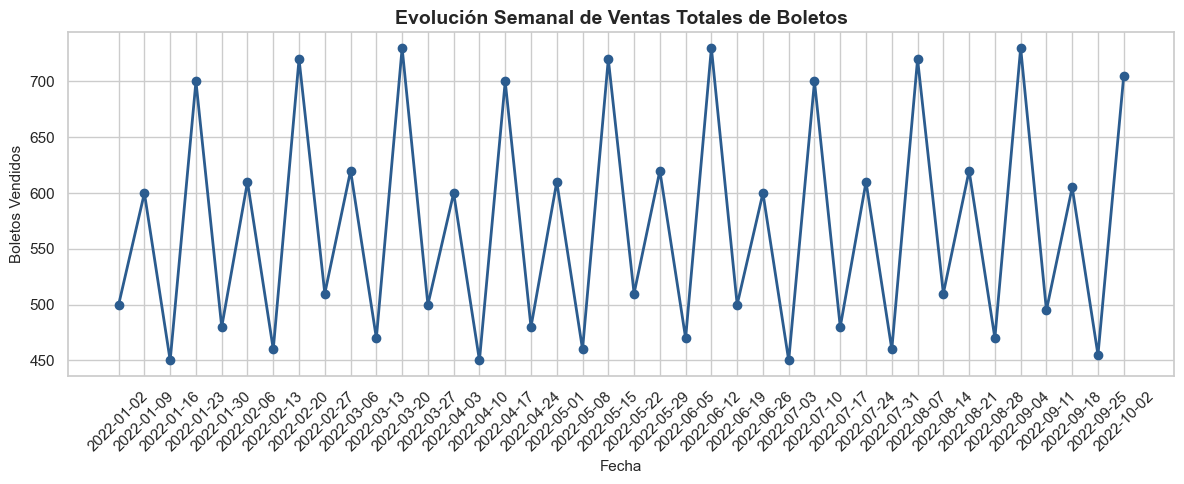

In [5]:
ventas_semanales = df_combinado.groupby('fecha')['ventas_boletos'].sum().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(ventas_semanales['fecha'], ventas_semanales['ventas_boletos'], marker='o', color='#2b5c8f', linewidth=2)
plt.title('Evolución Semanal de Ventas Totales de Boletos', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=11)
plt.ylabel('Boletos Vendidos', fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Y para el otro emplearemos un gráfico de barras

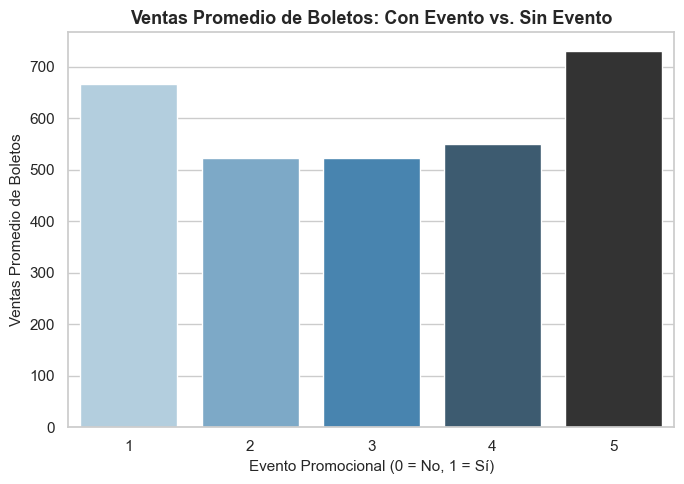

In [11]:
plt.figure(figsize=(7, 5))
sns.barplot(
    data=df_combinado, 
    x='eventos_promocionales', 
    y='ventas_boletos', 
    hue='eventos_promocionales', # Añadido para evitar el warning
    estimator=np.mean, 
    errorbar=None,
    palette='Blues_d',
    legend=False # Añadido para ocultar la leyenda redundante
)
plt.title('Ventas Promedio de Boletos: Con Evento vs. Sin Evento', fontsize=13, fontweight='bold')
plt.xlabel('Evento Promocional (0 = No, 1 = Sí)', fontsize=11)
plt.ylabel('Ventas Promedio de Boletos', fontsize=11)
plt.tight_layout()
plt.show()

# Análisis de outliers
Mediante un box plot vamos a identificar posibles outliers en las ventas de boletos.


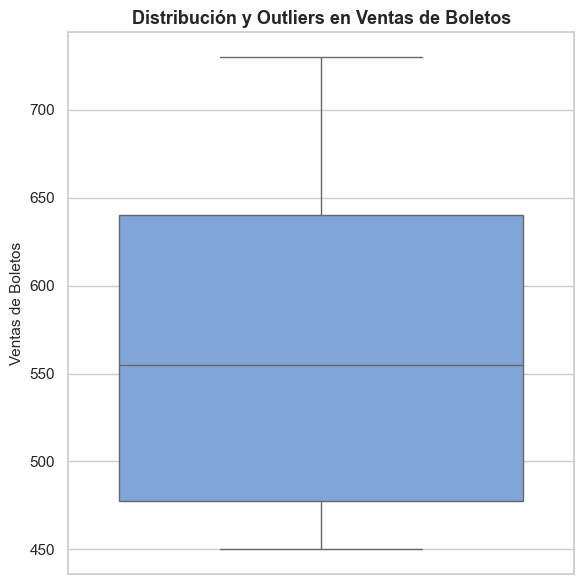

In [7]:
plt.figure(figsize=(6, 6))
sns.boxplot(y=df_combinado['ventas_boletos'], color='#72a1e5', flierprops=dict(marker='o', markerfacecolor='red', markersize=8))
plt.title('Distribución y Outliers en Ventas de Boletos', fontsize=13, fontweight='bold')
plt.ylabel('Ventas de Boletos', fontsize=11)
plt.tight_layout()
plt.show()

Al analizar el diagrama de caja de la variable `ventas_boletos`, se observa que todos los datos se encuentran dentro de los límites permitidos por el rango intercuartílico (no hay puntos individuales más allá de los bigotes superior e inferior). Por lo tanto, se detecta que no existen valores atípicos (outliers) en esta muestra, lo que significa que los datos son consistentes y no es necesario aplicar ninguna técnica de limpieza o eliminación matemática antes de entrenar el modelo de regresión.

# Análisis de correlación

Tras esto procedemos a analizar la correlación entre las diferentes variables. 

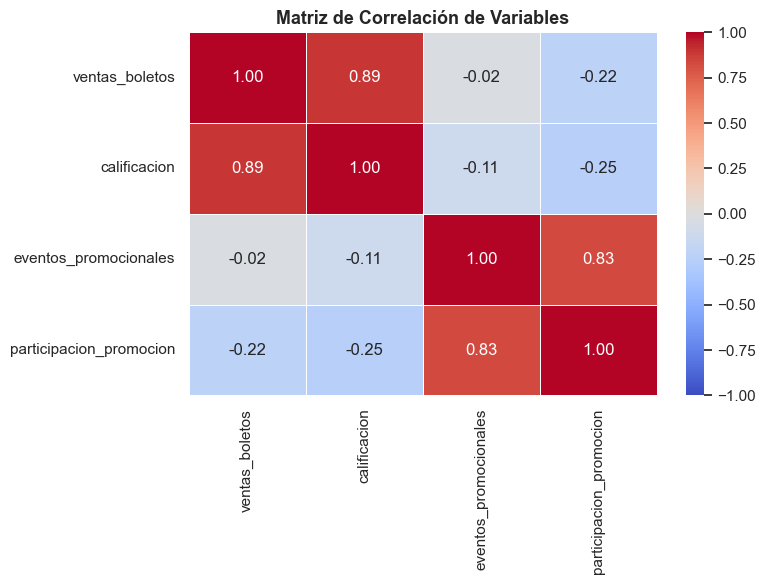

In [8]:
variables = ['ventas_boletos', 'calificacion', 'eventos_promocionales', 'participacion_promocion']
matriz_corr = df_combinado[variables].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlación de Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Modelo de regresión lineal

En este módulo procedemos a entrenar un modelo de regresión lineal para predecir las ventas de boletos a partir de las otras variables del dataset. 

In [9]:
X = df_combinado[['calificacion', 'eventos_promocionales', 'participacion_promocion']]
y = df_combinado['ventas_boletos']

X = sm.add_constant(X)

modelo = sm.OLS(y, X).fit()

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:         ventas_boletos   R-squared:                       0.811
Model:                            OLS   Adj. R-squared:                  0.796
Method:                 Least Squares   F-statistic:                     51.63
Date:                Tue, 21 Jul 2026   Prob (F-statistic):           4.03e-13
Time:                        16:52:31   Log-Likelihood:                -207.98
No. Observations:                  40   AIC:                             424.0
Df Residuals:                      36   BIC:                             430.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

# Visualización y evaluación del modelo

Por último vamos a realizar una predicción de las ventas de boletos y crear un gráfico que compare los valores reales frente a los predichos. Así, como solicitaremos un resumen completo del modelo para evaluar los coeficientes, el p-valor y el ajuste general (R²).


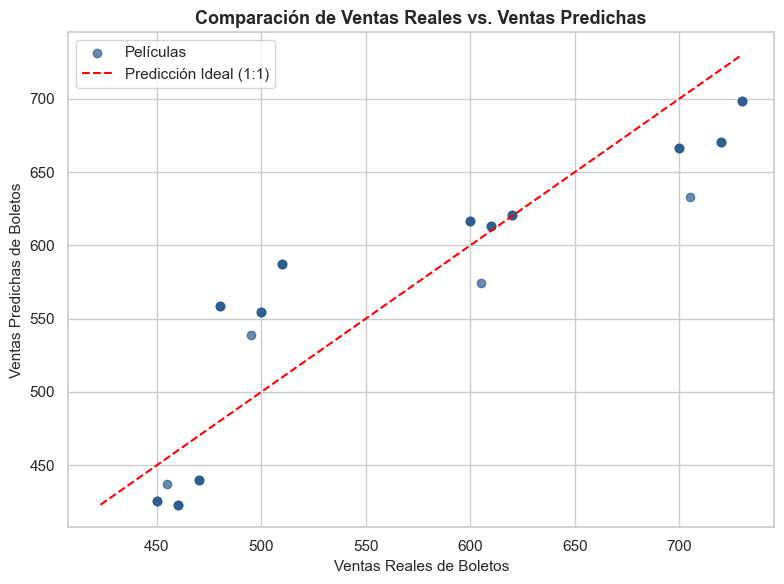

In [10]:
df_combinado['prediccion_ventas'] = modelo.predict(X)

plt.figure(figsize=(8, 6))
plt.scatter(df_combinado['ventas_boletos'], df_combinado['prediccion_ventas'], alpha=0.7, color='#2b5c8f', label='Películas')

min_val = min(df_combinado['ventas_boletos'].min(), df_combinado['prediccion_ventas'].min())
max_val = max(df_combinado['ventas_boletos'].max(), df_combinado['prediccion_ventas'].max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Predicción Ideal (1:1)')

plt.title('Comparación de Ventas Reales vs. Ventas Predichas', fontsize=13, fontweight='bold')
plt.xlabel('Ventas Reales de Boletos', fontsize=11)
plt.ylabel('Ventas Predichas de Boletos', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()